# Discrete delta hedging: where the P&L comes from

A trader sells an at-the-money call and hedges it with Black-Scholes delta, rebalancing a finite number of times. `pricing.hedging.delta_hedge_pnl` simulates the terminal P&L (in time-$T$ money). Questions:

1. **How spread out is the P&L** and how does it depend on the number of rebalancings?
2. **Implied vs. realised vol**: what is the mean P&L if the stock does not move with the vol you sold at?
3. **Hedging at the wrong vol**: does it matter *which* vol the delta is computed with?

`delta_hedge_pnl` has no dividend yield, so $q=0$ in this notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

from pricing.black_scholes import black_scholes_price
from pricing.hedging import delta_hedge_pnl

In [2]:
# Market parameters (same as previous notebooks, but without the dividend yield: hedging.py has none)
S0 = 100.0
K = 100.0
T = 1.0
r = 0.05
sigma = 0.20

premium = black_scholes_price(S0, K, T, r, sigma, "call")
print(f"Premium received for the call: {premium:.4f}")
n_paths = 20_000

Premium received for the call: 10.4506


## 1. P&L distribution vs. rebalancing frequency

Implied vol = realised vol = 20%, so in the continuous limit the hedge is perfect and the P&L is zero. With a finite number of rebalancings the P&L is a random variable with mean about zero and a spread that depends on $n$.

In [3]:
n_list = [4, 12, 52, 252, 1000]
pnl = {n: delta_hedge_pnl(S0, K, T, r, sigma, sigma, n, n_paths=n_paths, seed=3) for n in n_list}

rows = [{"rebalances": n, "mean": p.mean(), "std": p.std(), "std * sqrt(n)": p.std() * np.sqrt(n),
         "5th pct": np.percentile(p, 5), "95th pct": np.percentile(p, 95), "std / premium": p.std() / premium}
        for n, p in pnl.items()]
df_n = pd.DataFrame(rows)
df_n.round(4)

,rebalances,mean,std,std * sqrt(n),5th pct,95th pct,std / premium
0,4,-0.0083,3.2248,6.4496,-5.5300,5.0149,0.3086
1,12,0.0037,1.9438,6.7334,-3.2144,3.0991,0.1860
2,52,0.0082,0.9488,6.8419,-1.5493,1.5520,0.0908
3,252,0.0033,0.4359,6.9204,-0.7140,0.7057,0.0417
4,1000,0.0023,0.2221,7.0227,-0.3577,0.3621,0.0213


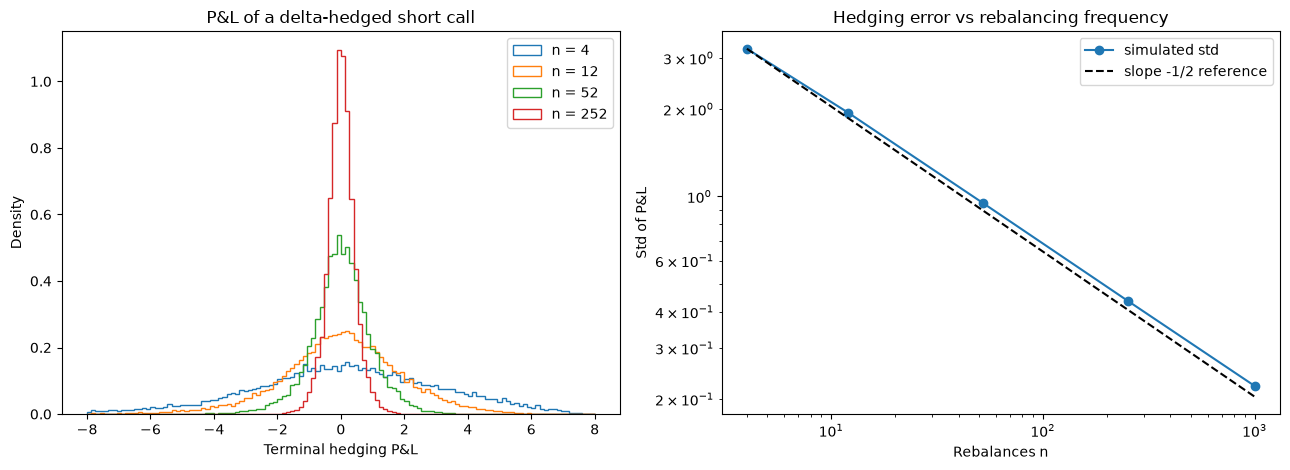

Fitted log-log slope of std vs n: -0.486
Skewness of P&L at n = 12: -0.44, at n = 252: -0.08


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for n in (4, 12, 52, 252):
    axes[0].hist(pnl[n], bins=120, range=(-8, 8), histtype="step", density=True, label=f"n = {n}")
axes[0].set_xlabel("Terminal hedging P&L"); axes[0].set_ylabel("Density"); axes[0].set_title("P&L of a delta-hedged short call"); axes[0].legend()

axes[1].loglog(df_n["rebalances"], df_n["std"], "o-", label="simulated std")
axes[1].loglog(df_n["rebalances"], df_n["std"].iloc[0] * np.sqrt(df_n["rebalances"].iloc[0] / df_n["rebalances"]), "k--", label="slope -1/2 reference")
axes[1].set_xlabel("Rebalances n"); axes[1].set_ylabel("Std of P&L"); axes[1].set_title("Hedging error vs rebalancing frequency"); axes[1].legend()
fig.tight_layout()
plt.show()

slope = np.polyfit(np.log(df_n["rebalances"]), np.log(df_n["std"]), 1)[0]
print(f"Fitted log-log slope of std vs n: {slope:.3f}")
print(f"Skewness of P&L at n = 12: {pd.Series(pnl[12]).skew():.2f}, at n = 252: {pd.Series(pnl[252]).skew():.2f}")

**Reading section 1**

- The mean is zero within noise for every $n$ (between $-0.008$ and $+0.008$), so discrete hedging with the right vol is unbiased: it is risk that is left, not edge.
- The standard deviation falls with slope $-0.49$ in log-log, and `std * sqrt(n)` is nearly constant (6.4 to 7.0). Cutting the hedging error in half needs four times as many rebalances. With 4 hedges the std is 31% of the premium, weekly (52) 9%, daily (252) 4.2%, and 1000 rebalances 2.1%.
- The distribution is visibly skewed with few rebalances (skewness $-0.44$ at $n=12$) and close to symmetric at $n=252$ ($-0.08$). The error comes from $\frac12\Gamma S^2\,(\Delta W^2-\sigma^2\Delta t)$ at each step: a centred but skewed variable, summed over $n$ steps.

## 2. Implied vs. realised vol

If you sell at $\sigma_{imp}$ and hedge at $\sigma_{imp}$ while the stock really moves with $\sigma_{real}$, the continuous-hedging P&L is

$$\text{P\&L} = \int_0^T e^{r(T-t)}\,\tfrac12\,\Gamma_{imp}(t,S_t)\,S_t^2\,\big(\sigma_{imp}^2-\sigma_{real}^2\big)\,dt.$$

The first-order intuition is "you earn $\frac12\Gamma S^2$ times the variance gap" at each instant: positive when you sold vol that turns out to be expensive ($\sigma_{imp}>\sigma_{real}$), negative otherwise. Taking expectations with $S_t$ following the real dynamics, the integral collapses to a closed form. By Ito on the option value under the *real* dynamics, $C(\sigma_{real})-C(\sigma_{imp})$ equals the expected discounted integral of $\frac12\Gamma S^2(\sigma_{real}^2-\sigma_{imp}^2)$, so

$$\mathbb{E}[\text{P\&L}] = e^{rT}\big(C(\sigma_{imp}) - C(\sigma_{real})\big).$$

The mean P&L is the difference in Black-Scholes prices between the vol you sold and the vol that happened. The theory is for continuous hedging, so the simulation uses 1000 rebalances. (A first attempt at checking this by numerically integrating the gamma expression came out off by about 2% at $\sigma_{real}=30\%$; the closed form is the one that matches the simulation.)

In [5]:
def expected_pnl_continuous(sigma_imp, sigma_real):
    return np.exp(r * T) * (black_scholes_price(S0, K, T, r, sigma_imp, "call") - black_scholes_price(S0, K, T, r, sigma_real, "call"))

rows = []
for sig_real in [0.10, 0.15, 0.20, 0.25, 0.30]:
    p = delta_hedge_pnl(S0, K, T, r, sigma, sig_real, 1000, n_paths=n_paths, seed=4)
    rows.append({"sigma_real": sig_real, "mean P&L (sim)": p.mean(), "se of mean": p.std() / np.sqrt(n_paths),
                 "theory (continuous)": expected_pnl_continuous(sigma, sig_real), "std": p.std(),
                 "P(P&L < 0)": (p < 0).mean()})
df_vol = pd.DataFrame(rows)
df_vol.round(4)

,sigma_real,mean P&L (sim),se of mean,theory (continuous),std,P(P&L < 0)
0,0.10,3.8356,0.0075,3.8325,1.0640,0.0000
1,0.15,1.9593,0.0048,1.9542,0.6789,0.0000
2,0.20,0.0029,0.0016,0.0000,0.2197,0.4922
3,0.25,-1.9802,0.0062,-1.9821,0.8796,1.0000
4,0.30,-3.9729,0.0129,-3.9745,1.8295,1.0000


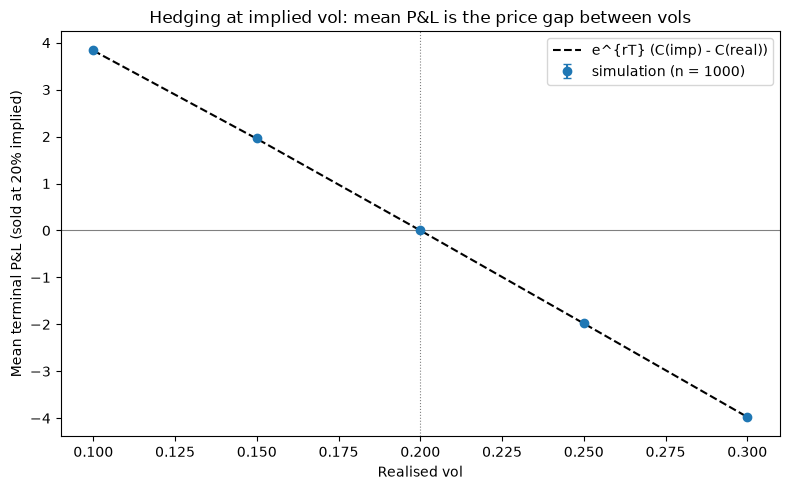

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(df_vol["sigma_real"], df_vol["mean P&L (sim)"], yerr=1.96 * df_vol["se of mean"], fmt="o", capsize=3, label="simulation (n = 1000)")
ax.plot(df_vol["sigma_real"], df_vol["theory (continuous)"], "k--", label="e^{rT} (C(imp) - C(real))")
ax.axhline(0, color="gray", linewidth=0.8); ax.axvline(sigma, color="gray", linewidth=0.8, linestyle=":")
ax.set_xlabel("Realised vol"); ax.set_ylabel("Mean terminal P&L (sold at 20% implied)")
ax.set_title("Hedging at implied vol: mean P&L is the price gap between vols")
ax.legend()
fig.tight_layout()
plt.show()

## 3. Hedging at the wrong vol

`delta_hedge_pnl` takes one vol for both the premium and the delta. The premium only adds a constant that grows at $r$, so the P&L of *selling* at $\sigma_{sold}$ but computing delta at $\sigma_h$ is

$$\text{P\&L}(\sigma_{sold},\sigma_h) = \text{P\&L}(\sigma_h,\sigma_h) + e^{rT}\big(C(\sigma_{sold}) - C(\sigma_h)\big),$$

where the first term is what the function returns when called with `sigma_imp=sigma_h`. The experiment: sold at 20%, the stock realises 30%, and the trader hedges with the delta at 20% (what they sold at), at 30% (what actually happens, known only with hindsight) or at 25%.

In [7]:
sig_sold, sig_real = 0.20, 0.30
n = 252
rows = []
dists = {}
for sig_h in [0.20, 0.25, 0.30]:
    base = delta_hedge_pnl(S0, K, T, r, sig_h, sig_real, n, n_paths=n_paths, seed=8)
    p = base + np.exp(r * T) * (black_scholes_price(S0, K, T, r, sig_sold, "call") - black_scholes_price(S0, K, T, r, sig_h, "call"))
    dists[sig_h] = p
    rows.append({"delta computed at": sig_h, "mean": p.mean(), "std": p.std(), "5th pct": np.percentile(p, 5), "95th pct": np.percentile(p, 95)})
print(f"e^(rT) * (C(30%) - C(20%)) = {np.exp(r*T)*(black_scholes_price(S0,K,T,r,0.30,'call')-black_scholes_price(S0,K,T,r,0.20,'call')):.4f}  (the P&L you lock in if you hedge at the realised vol)")
df_h = pd.DataFrame(rows)
df_h.round(4)

e^(rT) * (C(30%) - C(20%)) = 3.9745  (the P&L you lock in if you hedge at the realised vol)


,delta computed at,mean,std,5th pct,95th pct
0,0.20,-3.9640,1.9164,-7.3520,-1.2104
1,0.25,-3.9700,1.0461,-5.9011,-2.5648
2,0.30,-3.9733,0.6537,-5.0431,-2.9080


**Reading sections 2 and 3**

- With the delta hedged at the sold vol, the simulated mean is within about 2 standard errors of $e^{rT}(C(\sigma_{imp})-C(\sigma_{real}))$ at every realised vol: for example $-3.973\pm0.013$ at $\sigma_{real}=30\%$ against $-3.975$, and $+3.836\pm0.008$ against $+3.833$ at 10%. Selling 20% vol that realises at 30% loses about 3.97, which is 38% of the premium. When the stock realises less vol than sold the trade makes money in all simulated paths (P(P&L<0) = 0 at 10% and 15%) and when it realises more it loses in all of them at 25% and 30%. At equal vol the sign is a coin flip (49%).
- The spread is smallest when realised = implied (std 0.22) and grows on both sides (1.06 at 10%, 1.83 at 30%), because the P&L is then a path-dependent integral of gamma times the variance gap: it matters *where* the stock spends its time.
- Section 3: all three hedges have the same mean ($-3.964$, $-3.970$, $-3.973$ against the expected $-3.975$). What changes is the risk: the std is 1.92 when delta is computed at the sold 20%, 1.05 at 25% and 0.65 at the realised 30%, and the 5th percentile moves from $-7.35$ to $-5.04$. Hedging with the vol that actually happens makes the P&L almost path-independent: you lock in the price gap and the hedging error becomes the discretisation noise. The catch is that realised vol is only known afterwards; in practice the choice of hedging vol is a view on it.
- Nothing here includes transaction costs, which grow with the number of rebalances and work against the $\sqrt{n}$ law: there is an optimal frequency, not "as often as possible".

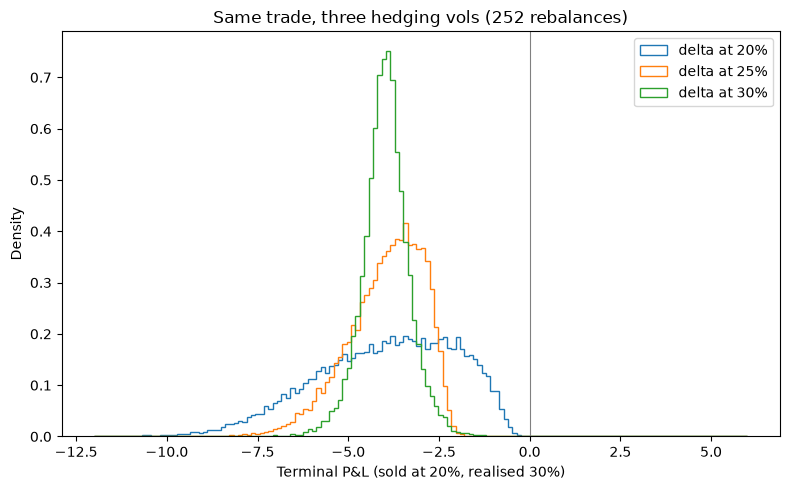

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
for sig_h, p in dists.items():
    ax.hist(p, bins=150, range=(-12, 6), histtype="step", density=True, label=f"delta at {sig_h:.0%}")
ax.axvline(0, color="gray", linewidth=0.8)
ax.set_xlabel("Terminal P&L (sold at 20%, realised 30%)")
ax.set_ylabel("Density")
ax.set_title("Same trade, three hedging vols (252 rebalances)")
ax.legend()
fig.tight_layout()
plt.show()